# TP2 — Machine Learning: Classificadores Probabilísticos e de Margem Máxima

Notebook organizado por exercício e tarefa. Reutiliza o Pipeline final do TP1, regerado na seção de preparação.<br>
Aluno: Guilherme Reis de Jesus Santos

## Preparação — Pipeline final do TP1

In [9]:
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, learning_curve, train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

plt.rcParams["figure.dpi"] = 110

In [10]:
%run pipeline_final_churn.py

Melhores parâmetros: {'classificador__C': 0.01}
ROC AUC (cv=5): 0.6578
ROC AUC no teste: 0.6640
              precision    recall  f1-score   support

           0      0.825     0.999     0.904      1979
           1      0.667     0.005     0.009       421

    accuracy                          0.825      2400
   macro avg      0.746     0.502     0.457      2400
weighted avg      0.797     0.825     0.747      2400

Pipeline salvo em pipeline_churn.joblib


In [11]:
from pipeline_final_churn import ARQUIVO, ARQUIVO_MODELO, COLUNAS_NUMERICAS, construir_pipeline, dividir_dados

pipeline = joblib.load(ARQUIVO_MODELO)
base = pd.read_csv(ARQUIVO)
X_train, X_test, y_train, y_test = dividir_dados()
proba = pipeline.predict_proba(X_test)[:, 1]

print(f"Pipeline carregado: {[nome for nome, _ in pipeline.steps]}")
print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")

Pipeline carregado: ['preprocessador', 'classificador']
X_train: (9600, 8) | X_test: (2400, 8)


## Exercício 1 — Matriz de confusão

### Tarefas 1 e 2 — Previsões, matriz e valores VP/FP/VN/FN

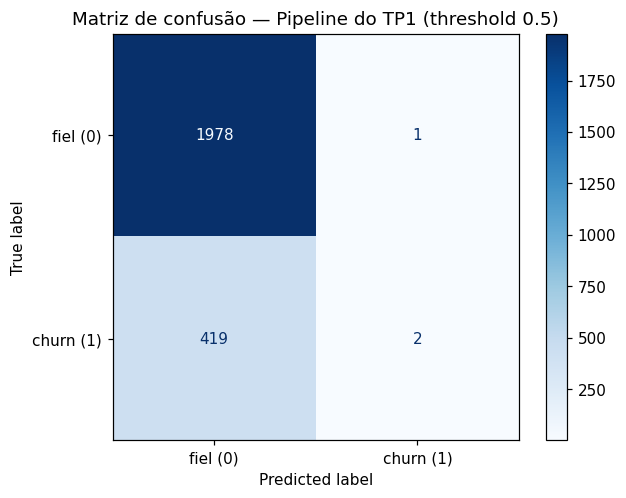

,assinantes
Verdadeiros positivos (VP),2
Falsos positivos (FP),1
Verdadeiros negativos (VN),1978
Falsos negativos (FN),419


In [12]:
y_pred = pipeline.predict(X_test)
matriz = confusion_matrix(y_test, y_pred)
vn, fp, fn, vp = matriz.ravel()

ConfusionMatrixDisplay(matriz, display_labels=["fiel (0)", "churn (1)"]).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusão — Pipeline do TP1 (threshold 0.5)")
plt.show()

pd.Series({
    "Verdadeiros positivos (VP)": vp,
    "Falsos positivos (FP)": fp,
    "Verdadeiros negativos (VN)": vn,
    "Falsos negativos (FN)": fn,
}, name="assinantes").to_frame()

### Tarefa 3 — Análise de negócio

#### ANALISE DA MATRIZ DE CONFUSAO

| célula | valor | significado para o negócio |
|---|---|---|
| Verdadeiros negativos (VN) | 1978 | Fiéis corretamente deixados em paz: nenhum desconto gasto à toa. |
| Falsos positivos (FP) | 1 | Fiel marcado como risco: recebe desconto sem precisar, é custo de campanha desperdiçado. |
| Falsos negativos (FN) | 419 | Assinantes que cancelaram **sem nenhum alerta**: receita recorrente perdida sem chance de retenção. |
| Verdadeiros positivos (VP) | 2 | Cancelamentos antecipados: únicos casos em que a campanha de retenção poderia agir. |

- **Custo do falso negativo:** é o erro caro aqui. Cada FN é um cliente que sai sem tentativa de retenção, o que significa perder as mensalidades futuras e ainda gastar para adquirir um substituto.
- **Custo do falso positivo:** é limitado ao valor do desconto concedido a quem ficaria de qualquer forma.
- **Leitura:** o modelo quase não dispara alertas (3 em 2400) e os alertas são confiáveis (2 de 3 acertam), mas ele deixa passar 419 de 421 cancelamentos (recall ≈ 0,5%). Com o threshold 0.5, a equipe de retenção **não pode contar** com o modelo para cobrir os cancelamentos.

## Exercício 2 — Tradeoff precisão × recall

### Tarefas 1 e 2 — Precisão e recall em vários thresholds

In [13]:
def metricas_por_threshold(y_real, probabilidades, thresholds):
    linhas = []
    for threshold in thresholds:
        y_previsto = (probabilidades >= threshold).astype(int)
        linhas.append({
            "threshold": threshold,
            "precisao": precision_score(y_real, y_previsto, zero_division=0),
            "recall": recall_score(y_real, y_previsto),
            "alertas": int(y_previsto.sum()),
        })
    return pd.DataFrame(linhas)


THRESHOLDS = [0.1, 0.15, 0.2, 0.3, 0.5, 0.7]

print("Distribuição das probabilidades previstas:")
print(pd.Series(proba).describe().round(3).to_string())
metricas_por_threshold(y_test, proba, THRESHOLDS).round(3)

Distribuição das probabilidades previstas:
count    2400.000
mean        0.176
std         0.080
min         0.017
25%         0.123
50%         0.168
75%         0.218
max         0.513


,threshold,precisao,recall,alertas
0,0.10,0.198,0.943,2008
1,0.15,0.228,0.791,1462
2,0.20,0.264,0.494,789
3,0.30,0.358,0.162,190
4,0.50,0.667,0.005,3
5,0.70,0.000,0.000,0


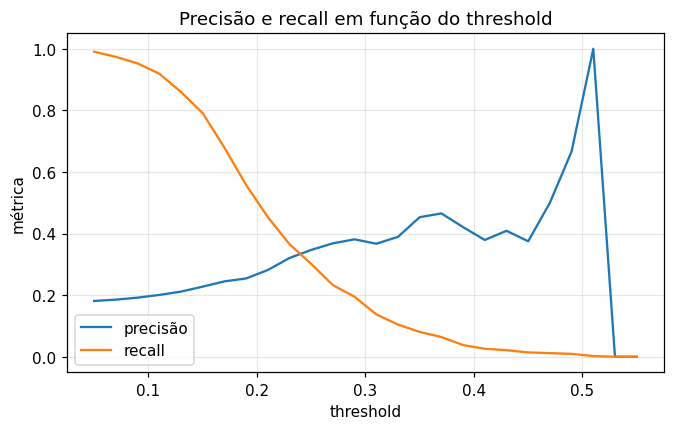

In [14]:
curva = metricas_por_threshold(y_test, proba, np.linspace(0.05, 0.55, 26))

plt.figure(figsize=(7, 4))
plt.plot(curva["threshold"], curva["precisao"], label="precisão")
plt.plot(curva["threshold"], curva["recall"], label="recall")
plt.xlabel("threshold")
plt.ylabel("métrica")
plt.title("Precisão e recall em função do threshold")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Tarefa 3 — Tabela e recomendação

#### TRADEOFF PRECISAO-RECALL

| threshold | precisão | recall | alertas (de 2400) |
|---|---|---|---|
| 0.10 | 0.198 | 0.943 | 2008 |
| 0.15 | 0.228 | 0.791 | 1462 |
| 0.20 | 0.264 | 0.494 | 789 |
| 0.30 | 0.358 | 0.162 | 190 |
| 0.50 (padrão) | 0.667 | 0.005 | 3 |
| 0.70 | 0.000 | 0.000 | 0 |

As probabilidades previstas ficam concentradas entre ~0,02 e ~0,51 (média ≈ 0,18, a taxa de churn da base), por isso o threshold padrão de 0.5 quase nunca dispara e o 0.7 nunca dispara. Baixar o threshold troca precisão por recall: a cada ponto de recall ganho, mais fiéis recebem desconto.

**Recomendação (priorizar não perder assinantes em risco):** usar o menor threshold da tabela, **0.10**, que captura 94% dos cancelamentos. O custo é alto: 2008 alertas (84% da base) com precisão de ≈ 20%, ou seja, praticamente uma campanha para todos, pois a precisão se aproxima da taxa de churn da base (17,6%). Recall de 100% só é possível sinalizando todos os assinantes. Se o orçamento de desconto for limitado, o 0.15 (recall 79% com 1462 alertas) ou o 0.20 são pontos de operação mais realistas.

## Exercício 3 — Curva ROC e AUC

### Tarefas 1 e 2 — Curva ROC, `roc_auc_score` e `RocCurveDisplay`

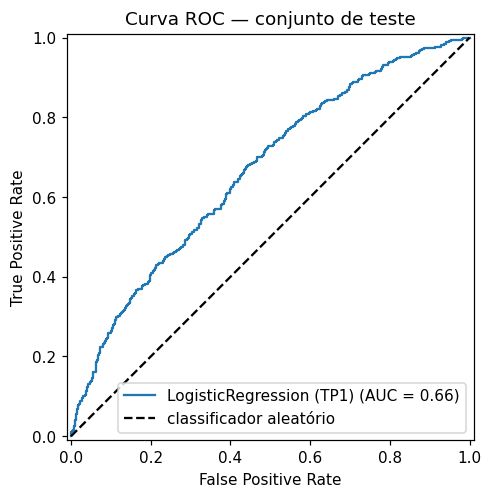

AUC-ROC: 0.6640


In [15]:
fpr, tpr, _ = roc_curve(y_test, proba)
auc = roc_auc_score(y_test, proba)

RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=auc, name="LogisticRegression (TP1)").plot()
plt.plot([0, 1], [0, 1], "k--", label="classificador aleatório")
plt.title("Curva ROC — conjunto de teste")
plt.legend()
plt.show()

print(f"AUC-ROC: {auc:.4f}")

### Tarefa 3 — Justificativa técnica

#### COMPARACAO AUC-ROC

- **Independe do threshold.** A curva ROC varre todos os limiares (TPR × FPR) e a AUC resume tudo em um número. Como o ponto de operação ainda está em negociação com o financeiro, comparar classificadores por precisão ou recall em um threshold fixo seria arbitrário.
- **Mede ranqueamento.** A AUC é a probabilidade de um assinante que cancelou receber score maior que um que ficou. Avalia a qualidade da ordenação, que é o que permite escolher o threshold depois.
- **Comparável entre modelos.** Serve inclusive para modelos que não produzem probabilidades calibradas (como o SVC, via `decision_function`), pois só depende da ordem dos scores.
- **Escala fixa:** 0,5 equivale a acaso e 1,0 a separação perfeita. O AUC de **0,664** indica ranqueamento fraco, acima do acaso, mas distante de um modelo forte, o que é coerente com o recall baixo do Exercício 2.
- **Limitação:** com classes desbalanceadas (≈ 18% de churn), a AUC pode parecer melhor do que a utilidade prática; por isso ela complementa, e não substitui, a análise de precisão e recall no threshold escolhido.

## Exercício 4 — Demonstração da sigmoide

### Tarefa 1 — Coeficientes e intercepto

In [16]:
preprocessador = pipeline.named_steps["preprocessador"]
modelo = pipeline.named_steps["classificador"]

coeficientes = pd.Series(modelo.coef_[0], index=preprocessador.get_feature_names_out(), name="coef_")
print(f"intercept_: {modelo.intercept_[0]:.4f}")
coeficientes.round(4).to_frame()

intercept_: -1.6503


,coef_
numericas__tempo_assinatura_meses,-0.4803
numericas__uso_medio_semanal_horas,-0.2034
numericas__numero_reclamacoes,0.3110
categoricas__plano_basico,0.0159
categoricas__plano_padrao,0.0309
categoricas__plano_premium,-0.0475
categoricas__metodo_pagamento_boleto,0.0215
categoricas__metodo_pagamento_cartao_credito,-0.0234
categoricas__metodo_pagamento_pix,0.0012
categoricas__dispositivo_principal_celular,-0.0182


### Tarefas 2 e 3 — Cálculo manual (combinação linear + sigmoide) × `predict_proba`

In [17]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def escolher_assinantes(probabilidades):
    ordem = np.argsort(probabilidades)
    return [ordem[0], ordem[len(ordem) // 2], ordem[-1]]


indices = escolher_assinantes(proba)
assinantes = X_test.iloc[indices]

features = preprocessador.transform(assinantes)
combinacao_linear = features @ modelo.coef_[0] + modelo.intercept_[0]

comparacao = pd.DataFrame({
    "cliente_id": assinantes["cliente_id"].values,
    "z (combinação linear)": combinacao_linear,
    "sigmoid(z) manual": sigmoid(combinacao_linear),
    "predict_proba": pipeline.predict_proba(assinantes)[:, 1],
})
comparacao["diferença"] = (comparacao["sigmoid(z) manual"] - comparacao["predict_proba"]).abs()
comparacao.round(6)

,cliente_id,z (combinação linear),sigmoid(z) manual,predict_proba,diferença
0,AST-02841,-4.059737,0.016961,0.016961,0.0
1,AST-06809,-1.600212,0.167952,0.167952,0.0
2,AST-10516,0.050962,0.512738,0.512738,0.0


#### DEMONSTRACAO SIGMOIDE


A regressão logística calcula primeiro a **combinação linear** das 13 features já pré-processadas, $z = w \cdot x + b$ (com `intercept_` = −1,6503), um número que pode ir de −∞ a +∞. Depois aplica a **sigmoide**, que o comprime para o intervalo (0, 1):

$$P(\text{churn} \mid x) = \sigma(z) = \frac{1}{1 + e^{-z}}$$

Com $z = 0$ a probabilidade é 0,5; quanto mais negativo o $z$, mais perto de 0; quanto mais positivo, mais perto de 1.

| assinante | z | sigmoid(z) manual | predict_proba | diferença |
|---|---|---|---|---|
| menor risco (AST-02841) | −4.0597 | 0.016961 | 0.016961 | 0 |
| risco mediano (AST-06809) | −1.6002 | 0.167952 | 0.167952 | 0 |
| maior risco (AST-10516) | 0.0510 | 0.512738 | 0.512738 | 0 |

O cálculo manual coincide com `predict_proba` (diferença zero na precisão exibida), o que comprova que o modelo é exatamente $\sigma(w \cdot x + b)$. Os coeficientes (features padronizadas, logo comparáveis) têm sinais coerentes: mais reclamações aumentam o logit de churn (+0,31), enquanto mais tempo de assinatura (−0,48) e mais uso (−0,20) o reduzem; as categóricas ficam perto de zero. Além disso, a maior probabilidade do teste é ≈ 0,51, o que explica por que o threshold 0.5 quase nunca dispara.

## Exercício 5 — Regressão logística multiclasse (alvo: `plano`)

### Tarefas 1 e 2 — Treino e `classification_report`

In [18]:
def treinar_classificador_plano(df):
    X = df[COLUNAS_NUMERICAS]
    y = df["plano"]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    classificador = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_tr, y_tr)
    return classificador, X_te, y_te


classificador_plano, X_plano_test, y_plano_test = treinar_classificador_plano(base)
y_plano_pred = classificador_plano.predict(X_plano_test)

print(classification_report(y_plano_test, y_plano_pred, zero_division=0))

f1_por_classe = pd.Series(
    f1_score(y_plano_test, y_plano_pred, average=None, zero_division=0),
    index=classificador_plano.classes_,
)
print(f"Classe com pior desempenho: {f1_por_classe.idxmin()} (f1 = {f1_por_classe.min():.2f})")

              precision    recall  f1-score   support

      basico       0.41      0.86      0.55       972
      padrao       0.41      0.15      0.22       937
     premium       0.00      0.00      0.00       491

    accuracy                           0.41      2400
   macro avg       0.27      0.34      0.26      2400
weighted avg       0.32      0.41      0.31      2400

Classe com pior desempenho: premium (f1 = 0.00)


**Leitura:** a classe com pior desempenho é **premium** (precisão, recall e f1 iguais a zero): ela é a minoritária (20%) e o modelo nunca a prevê. A acurácia global (≈ 41%) é praticamente a da classe majoritária, ou seja, as três features numéricas trazem pouco ou nenhum sinal sobre o plano nesta base; o resultado é compatível com a variável `plano` ser independente dessas features.

### Tarefa 3 — Softmax

#### REGRESSAO LOGISTICA MULTICLASSE

Para K classes, o modelo calcula **uma combinação linear por classe**, $z_k = w_k \cdot x + b_k$ (no sklearn, `coef_` tem uma linha por classe), e converte os scores em probabilidades com a softmax:

$$P(y = k \mid x) = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}$$

As probabilidades ficam entre 0 e 1 e somam 1, e a classe prevista é a de maior probabilidade. Com **K = 2** a softmax reduz exatamente à sigmoide:

$$P(y = 1 \mid x) = \frac{e^{z_1}}{e^{z_0} + e^{z_1}} = \frac{1}{1 + e^{-(z_1 - z_0)}} = \sigma(z_1 - z_0)$$

Ou seja, a sigmoide binária é a softmax de duas classes em que só importa a diferença entre os dois scores. Com três classes (basico, padrao, premium) o modelo tem três vetores de pesos e a softmax normaliza os três scores em uma distribuição de probabilidade; o treino minimiza a entropia cruzada multiclasse.

## Exercício 6 — Curvas de aprendizado e regularização Ridge

As curvas usam `roc_auc` (a mesma métrica do TP1), pois com ~18% de churn a acurácia fica quase constante e não revelaria o gap treino/validação.

### Tarefas 1 e 2 — `learning_curve` para três valores de C e gráficos

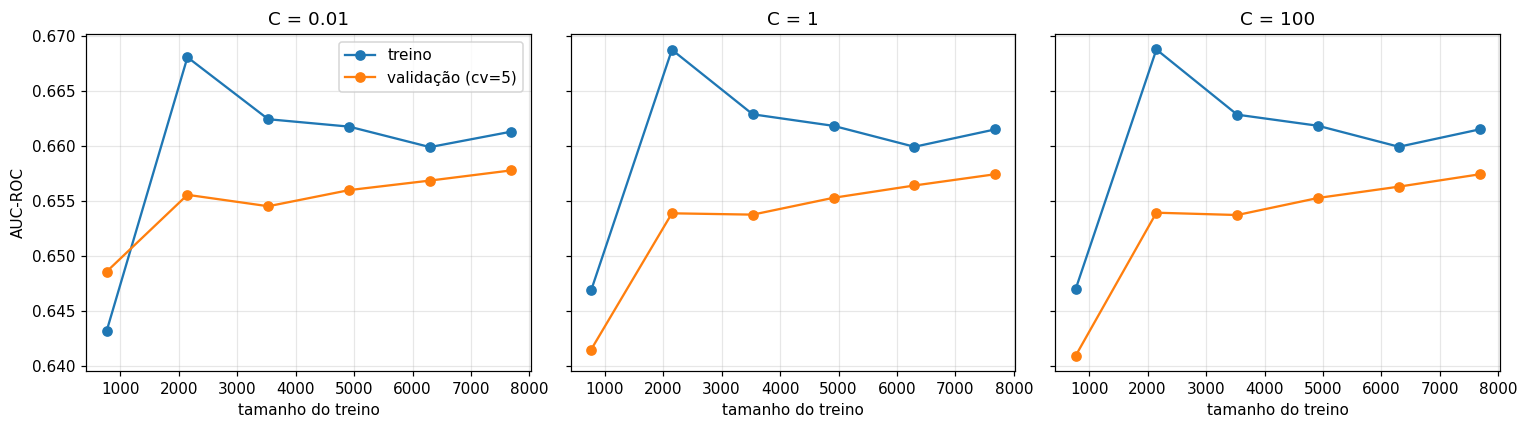

,C,auc_treino,auc_validacao,gap
0,0.01,0.6613,0.6578,0.0035
1,1.00,0.6615,0.6574,0.0041
2,100.00,0.6615,0.6574,0.0041


In [19]:
VALORES_C = [0.01, 1, 100]
TAMANHOS_TREINO = np.linspace(0.1, 1.0, 6)


def curva_de_aprendizado(c):
    estimador = construir_pipeline().set_params(classificador__C=c)
    tamanhos, treino, validacao = learning_curve(
        estimador, X_train, y_train, train_sizes=TAMANHOS_TREINO, cv=5, scoring="roc_auc", n_jobs=-1
    )
    return tamanhos, treino.mean(axis=1), validacao.mean(axis=1)


curvas = {c: curva_de_aprendizado(c) for c in VALORES_C}

fig, eixos = plt.subplots(1, len(VALORES_C), figsize=(14, 4), sharey=True)
for eixo, (c, (tamanhos, treino, validacao)) in zip(eixos, curvas.items()):
    eixo.plot(tamanhos, treino, "o-", label="treino")
    eixo.plot(tamanhos, validacao, "o-", label="validação (cv=5)")
    eixo.set_title(f"C = {c}")
    eixo.set_xlabel("tamanho do treino")
    eixo.grid(alpha=0.3)
eixos[0].set_ylabel("AUC-ROC")
eixos[0].legend()
plt.tight_layout()
plt.show()

pd.DataFrame([
    {"C": c, "auc_treino": treino[-1], "auc_validacao": validacao[-1], "gap": treino[-1] - validacao[-1]}
    for c, (_, treino, validacao) in curvas.items()
]).round(4)

### Tarefa 3 — Recomendação

#### ANALISE DA REGULARIZACAO RIDGE


| C | AUC treino | AUC validação | gap |
|---|---|---|---|
| 0.01 | 0.6613 | 0.6578 | 0.0035 |
| 1 | 0.6615 | 0.6574 | 0.0041 |
| 100 | 0.6615 | 0.6574 | 0.0041 |

- **Diagnóstico:** o overfitting suspeitado **não aparece**. O gap treino/validação é menor que 0,5 ponto de AUC nos três casos, e as duas curvas convergem e estabilizam a partir de uma fração pequena do treino. O desempenho é limitado pelo sinal fraco das features (bias), não pela variância. Mais dados trariam ganho mínimo.
- **Efeito de C:** a regularização Ridge quase não altera o resultado; os três valores empatam dentro do desvio entre folds (≈ 0,01 no TP1).
- **Recomendação: C = 0.01.** Tem o menor gap (0,0035) e a melhor AUC de validação (0,6578), ou seja, reduz a diferença entre treino e validação sem perder desempenho, e é a escolha mais conservadora, a mesma do `GridSearchCV` do TP1. Valores maiores (1 e 100) não ganham nada e deixam o modelo um pouco mais solto.

## Exercício 7 — SVM linear e margem máxima (`ltv_alto`)

Features escolhidas: `tempo_assinatura_meses` e `uso_medio_semanal_horas`, as duas que descrevem os assinantes de alto valor (alto LTV = tempo e uso acima da média). As features são padronizadas antes do SVM, e os gráficos voltam à escala original.

### Tarefas 1 e 2 — `SVC(kernel='linear')`, fronteira e vetores de suporte

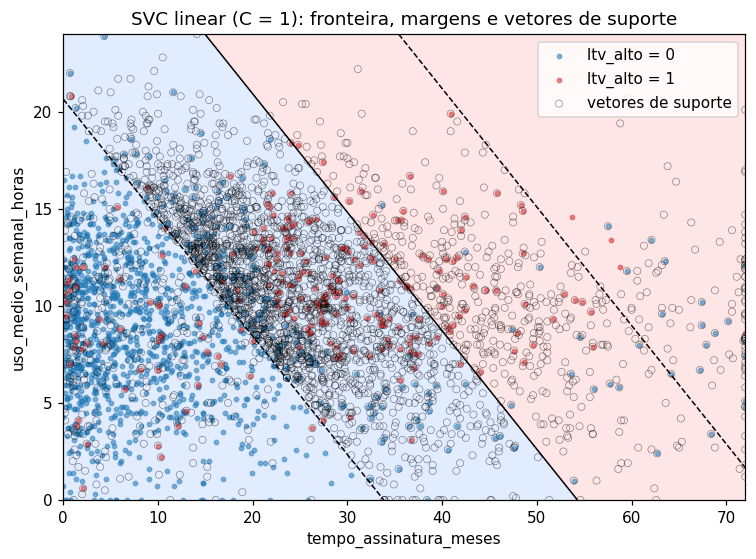

Vetores de suporte: 3032 de 9600
Acurácia no teste: 0.8562
Proporção de ltv_alto = 0 no teste (acurácia do chute 'sempre 0'): 0.8379


In [20]:
FEATURES_LTV = ["tempo_assinatura_meses", "uso_medio_semanal_horas"]


def dividir_ltv(df):
    X = df[FEATURES_LTV]
    y = df["ltv_alto"]
    return train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)


def construir_svm(kernel, c):
    return make_pipeline(StandardScaler(), SVC(kernel=kernel, C=c))


def plotar_fronteira(eixo, modelo, X, y, titulo):
    x1 = np.linspace(X.iloc[:, 0].min(), X.iloc[:, 0].max(), 300)
    x2 = np.linspace(X.iloc[:, 1].min(), X.iloc[:, 1].max(), 300)
    malha_x, malha_y = np.meshgrid(x1, x2)
    malha = pd.DataFrame(np.c_[malha_x.ravel(), malha_y.ravel()], columns=X.columns)
    score = modelo.decision_function(malha).reshape(malha_x.shape)

    eixo.contourf(malha_x, malha_y, score, levels=[-np.inf, 0, np.inf], colors=["#cfe0ff", "#ffd6d6"], alpha=0.6)
    eixo.contour(malha_x, malha_y, score, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=1)

    amostra = X.sample(1500, random_state=0)
    rotulos = y.loc[amostra.index]
    for classe, cor in [(0, "tab:blue"), (1, "tab:red")]:
        pontos = amostra[rotulos == classe]
        eixo.scatter(pontos.iloc[:, 0], pontos.iloc[:, 1], s=8, c=cor, alpha=0.5, label=f"ltv_alto = {classe}")

    vetores = modelo[0].inverse_transform(modelo[-1].support_vectors_)
    eixo.scatter(vetores[:, 0], vetores[:, 1], s=22, facecolors="none", edgecolors="k", linewidths=0.4, alpha=0.5, label="vetores de suporte")
    eixo.set_xlabel(X.columns[0])
    eixo.set_ylabel(X.columns[1])
    eixo.set_title(titulo)


X_ltv_train, X_ltv_test, y_ltv_train, y_ltv_test = dividir_ltv(base)

svm_linear = construir_svm("linear", 1).fit(X_ltv_train, y_ltv_train)

fig, eixo = plt.subplots(figsize=(8, 5.5))
plotar_fronteira(eixo, svm_linear, X_ltv_train, y_ltv_train, "SVC linear (C = 1): fronteira, margens e vetores de suporte")
eixo.legend(loc="upper right")
plt.show()

print(f"Vetores de suporte: {len(svm_linear[-1].support_vectors_)} de {len(X_ltv_train)}")
print(f"Acurácia no teste: {accuracy_score(y_ltv_test, svm_linear.predict(X_ltv_test)):.4f}")
print(f"Proporção de ltv_alto = 0 no teste (acurácia do chute 'sempre 0'): {(y_ltv_test == 0).mean():.4f}")

### Tarefa 3 — Papel dos vetores de suporte

#### SVM MARGEM MAXIMA

- **O que o SVM faz:** escolhe o hiperplano que **maximiza a margem**, a distância até os pontos mais próximos de cada classe.
- **Papel dos vetores de suporte:** são os pontos que ficam sobre a margem ou dentro dela (círculos no gráfico). Só eles têm peso diferente de zero na solução, $w = \sum_i \alpha_i y_i x_i$. Se qualquer outro ponto for removido ou deslocado (sem entrar na margem), a fronteira **não muda**.
- **Diferença para a `LogisticRegression`:** ela maximiza a verossimilhança com **todos** os pontos, e cada observação contribui para o gradiente (mesmo as bem classificadas e distantes, com peso menor). Mover um ponto qualquer desloca a fronteira. No SVM, a perda hinge é zero para pontos corretamente classificados fora da margem.
- **Limite deste protótipo:** na prática, as classes não são separáveis por uma reta. A região de alto valor é uma "ilha" no espaço tempo × uso, e a fronteira linear só ganha pouco sobre o chute "sempre 0" (acurácia 0,856 contra 0,838). Isso motiva os Exercícios 8 e 9.

## Exercício 8 — Soft margin: efeito do parâmetro C

### Tarefas 1 e 2 — Três valores de C: vetores de suporte e acurácia no teste

In [21]:
VALORES_C_SVM = [0.01, 1, 100]


def avaliar_svm_linear(c):
    inicio = time.perf_counter()
    modelo_svm = construir_svm("linear", c).fit(X_ltv_train, y_ltv_train)
    return {
        "C": c,
        "vetores_de_suporte": len(modelo_svm[-1].support_vectors_),
        "acuracia_treino": accuracy_score(y_ltv_train, modelo_svm.predict(X_ltv_train)),
        "acuracia_teste": accuracy_score(y_ltv_test, modelo_svm.predict(X_ltv_test)),
        "tempo_fit_s": time.perf_counter() - inicio,
    }


resultados_c = pd.DataFrame([avaliar_svm_linear(c) for c in VALORES_C_SVM])
resultados_c.round(4)

,C,vetores_de_suporte,acuracia_treino,acuracia_teste,tempo_fit_s
0,0.01,3077,0.8500,0.8492,0.6583
1,1.00,3032,0.8567,0.8562,0.9722
2,100.00,3033,0.8567,0.8562,31.5559


### Tarefa 3 — Melhor equilíbrio bias-variância

#### AJUSTE SOFT MARGIN

O parâmetro C penaliza violações da margem: **C pequeno** = margem larga, tolera muitos erros (bias alto, variância baixa); **C grande** = margem estreita, tolera poucos erros (bias baixo, variância alta, risco de overfitting).

- **C = 0.01:** menor acurácia (0,849 no teste) e o maior número de vetores de suporte (3077). A margem larga demais simplifica o modelo além do necessário (bias).
- **C = 1 e C = 100:** a acurácia no teste é a mesma (0,856) e o número de vetores de suporte é praticamente igual (≈ 3030). Treino e teste ficam sempre próximos (gap < 1 p.p.), então **não há problema de variância**: o limite é de bias, porque uma reta não descreve a região curva de alto valor.
- **Escolha: C = 1.** Chega ao mesmo desempenho que C = 100, com a menor complexidade necessária e com tempo de treino muito menor (coluna `tempo_fit_s`). Aumentar C além disso só custa processamento sem ganho.

Nota: nenhum valor de C resolve o limite do kernel linear; é o que o Exercício 9 ataca.

In [22]:
def escolher_melhor_c(resultados):
    ordenado = resultados.sort_values(["acuracia_teste", "C"], ascending=[False, True])
    return ordenado.iloc[0]["C"]


melhor_c = escolher_melhor_c(resultados_c)
print(f"Melhor C (maior acurácia de teste, desempate pelo menor C): {melhor_c}")

Melhor C (maior acurácia de teste, desempate pelo menor C): 1.0


## Exercício 9 — Kernel RBF

### Tarefas 1 e 2 — `SVC(kernel='rbf')` × linear, lado a lado

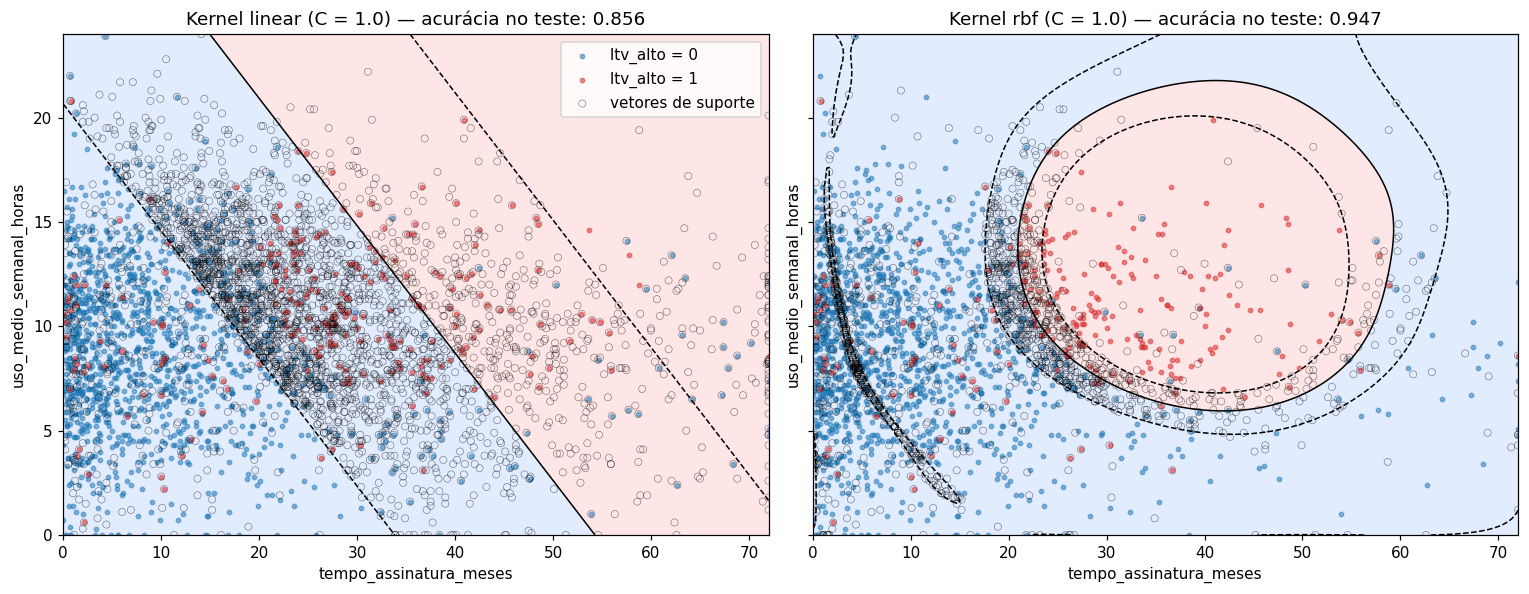

,acuracia_teste,vetores_de_suporte
linear,0.8562,3032
rbf,0.9471,1562


In [23]:
svm_linear_melhor = construir_svm("linear", melhor_c).fit(X_ltv_train, y_ltv_train)
svm_rbf = construir_svm("rbf", melhor_c).fit(X_ltv_train, y_ltv_train)

modelos_ltv = {"linear": svm_linear_melhor, "rbf": svm_rbf}
acuracias = {nome: accuracy_score(y_ltv_test, m.predict(X_ltv_test)) for nome, m in modelos_ltv.items()}

fig, eixos = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for eixo, (nome, m) in zip(eixos, modelos_ltv.items()):
    plotar_fronteira(eixo, m, X_ltv_train, y_ltv_train, f"Kernel {nome} (C = {melhor_c}) — acurácia no teste: {acuracias[nome]:.3f}")
eixos[0].legend(loc="upper right")
plt.tight_layout()
plt.show()

pd.DataFrame({
    "acuracia_teste": acuracias,
    "vetores_de_suporte": {nome: len(m[-1].support_vectors_) for nome, m in modelos_ltv.items()},
}).round(4)

### Tarefa 3 — Por que o RBF separa classes não linearmente

#### KERNEL RBF

- **Kernel trick:** a formulação dual do SVM usa os dados apenas por produtos internos $\langle x_i, x_j \rangle$. Trocar esse produto por $K(x, x') = e^{-\gamma \lVert x - x' \rVert^2}$ equivale a calcular o produto interno em um espaço de dimensão muito alta (infinita, no caso do RBF), **sem nunca construir** as novas coordenadas: o valor de $K$ é calculado direto no espaço original.
- **Função de decisão:** $f(x) = \sum_i \alpha_i y_i K(x_i, x) + b$, uma soma de "bolhas" centradas nos vetores de suporte, em que cada bolha mede a similaridade com um ponto. A soma de bolhas produz fronteiras curvas, como a região elíptica de `ltv_alto`.
- **Hiperparâmetros:** $\gamma$ controla a largura das bolhas (valor alto = fronteira recortada, risco de overfitting; valor baixo = suave) e C controla a tolerância a erros, como no kernel linear.
- **Resultado aqui:** o RBF sobe a acurácia de teste de ≈ 0,856 (linear) para ≈ 0,947, e a fronteira acompanha o formato curvo da região de alto valor.

## Exercício 10 — Decisão do modelo de churn: LogisticRegression × SVC RBF

### Tarefa 1 — `SVC(kernel='rbf')` com C ajustado por `GridSearchCV`

In [24]:
GRADE_C_SVC = {"classificador__C": [0.1, 1, 10]}


def construir_pipeline_svc():
    return Pipeline([
        ("preprocessador", clone(pipeline.named_steps["preprocessador"])),
        ("classificador", SVC(kernel="rbf")),
    ])


busca_svc = GridSearchCV(construir_pipeline_svc(), GRADE_C_SVC, cv=5, scoring="roc_auc", n_jobs=-1)
busca_svc.fit(X_train, y_train)
svc_churn = busca_svc.best_estimator_

print("best_params_:", busca_svc.best_params_)
print(f"best_score_ (ROC AUC, cv=5): {busca_svc.best_score_:.4f}")

best_params_: {'classificador__C': 1}
best_score_ (ROC AUC, cv=5): 0.5629


### Tarefa 2 — Comparação lado a lado no mesmo `X_test`

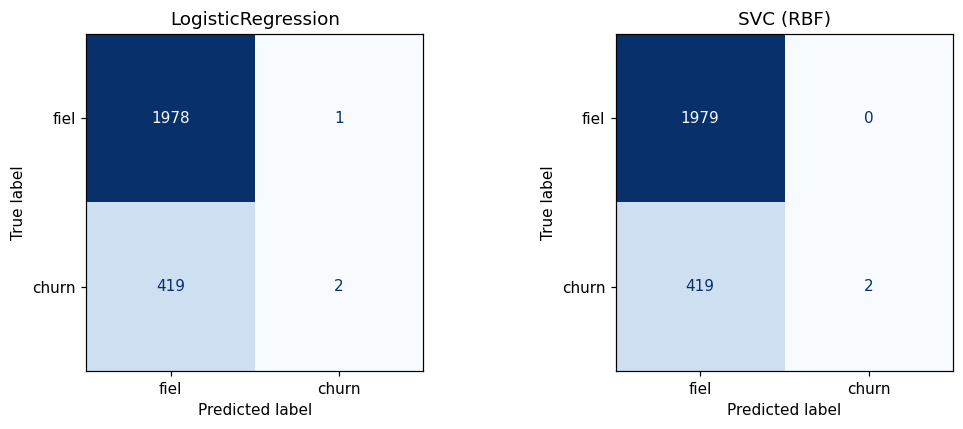

,VN,FP,FN,VP,precisao,recall,auc_roc
LogisticRegression,1978.0,1.0,419.0,2.0,0.6667,0.0048,0.6640
SVC (RBF),1979.0,0.0,419.0,2.0,1.0000,0.0048,0.5482


In [25]:
def metricas_do_modelo(modelo):
    y_previsto = modelo.predict(X_test)
    vn, fp, fn, vp = confusion_matrix(y_test, y_previsto).ravel()
    return {
        "VN": vn, "FP": fp, "FN": fn, "VP": vp,
        "precisao": precision_score(y_test, y_previsto, zero_division=0),
        "recall": recall_score(y_test, y_previsto),
        "auc_roc": roc_auc_score(y_test, modelo.decision_function(X_test)),
    }


modelos_churn = {"LogisticRegression": pipeline, "SVC (RBF)": svc_churn}

fig, eixos = plt.subplots(1, 2, figsize=(10, 4))
for eixo, (nome, m) in zip(eixos, modelos_churn.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, display_labels=["fiel", "churn"], cmap="Blues", ax=eixo, colorbar=False)
    eixo.set_title(nome)
plt.tight_layout()
plt.show()

pd.DataFrame({nome: metricas_do_modelo(m) for nome, m in modelos_churn.items()}).T.round(4)

### Tarefa 3 — Recomendação final

#### DECISAO MODELO CHURN


| modelo | VN | FP | FN | VP | precisão | recall | AUC-ROC (teste) | AUC (cv=5) |
|---|---|---|---|---|---|---|---|---|
| LogisticRegression | 1978 | 1 | 419 | 2 | 0.667 | 0.005 | **0.664** | 0.658 |
| SVC (RBF), C = 1 | 1979 | 0 | 419 | 2 | 1.000 | 0.005 | 0.548 | 0.563 |

**Recomendação: levar a `LogisticRegression` para produção.**

1. **Ranqueamento:** a AUC-ROC da regressão logística (0,664) é bem superior à do SVC RBF (0,548, quase acaso), e a validação cruzada mostra o mesmo (0,658 × 0,563). Como o threshold ainda será negociado, o que importa é a qualidade do ranqueamento, e é nela que o SVC perde.
2. **Custo do falso negativo (Exercício 1):** no threshold padrão os dois modelos deixam passar os mesmos 419 de 421 cancelamentos. A precisão de 1,00 do SVC vem de apenas 2 alertas e não é evidência de qualidade. Para reduzir FN é preciso baixar o threshold (Exercício 2), e isso só funciona se o score ordenar bem os assinantes, o que a regressão logística faz e o SVC não.
3. **Natureza do problema:** o RBF brilhou no `ltv_alto` (0,947 contra 0,856) porque aquela fronteira é curva. No churn não há estrutura não linear a capturar; o resultado indica que a relação é bem descrita por uma combinação linear no logit, e o RBF só acrescenta variância.
4. **Operação:** a regressão logística entrega probabilidades diretas, coeficientes interpretáveis (Exercício 4) e treino e inferência mais baratos, o que facilita explicar os alertas para a retenção.

**Ressalva:** com AUC ≈ 0,66 o modelo escolhido ainda é fraco. Para uso real, a recomendação é operá-lo com threshold reduzido (0.15 a 0.20, conforme o orçamento de desconto, como na tabela do Exercício 2) e buscar melhoria com novas features, não com um classificador mais complexo.